## Section 3: Hierarchal modeling
A key strength of Bayesian modeling is the easy and flexibility with which one can implement a hierarchical model. This section will implement and compare a pooled & partially pooled model.

In [1]:
import itertools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import scipy
import scipy.stats as stats
import seaborn as sns # .apionly

from IPython.display import Image
from sklearn import preprocessing


%matplotlib inline
plt.style.use('bmh')
colors = ['#348ABD', '#A60628', '#7A68A6', '#467821', '#D55E00',
          '#CC79A7', '#56B4E9', '#009E73', '#F0E442', '#0072B2']

# messages = pd.read_csv('data/hangout_chat_data.csv')

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


ModuleNotFoundError: No module named 'sklearn'

### Model (Un)Pooling
Let's explore a different way of modeling the response time for my hangout conversations. My intuition would suggest that my tendency to reply quickly to a chat depends on who I'm talking to. I might be more likely to respond quickly to my girlfriend than to a distant friend. As such, I could decide to model each conversation independently, estimating parameters $\mu_i$ and $\alpha_i$ for each conversation $i$.

One consideration we must make, is that some conversations have very few messages compared to others. As such, our estimates of response time for conversations with few messages will have a higher degree of uncertainty than conversations with a large number of messages. The below plot illustrates the discrepancy in sample size per conversation.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import pickle as pkl

colab = True
if colab:
  messages = pkl.load(open("../data/hangout_chat_data.pkl", 'rb'))

Mounted at /content/drive


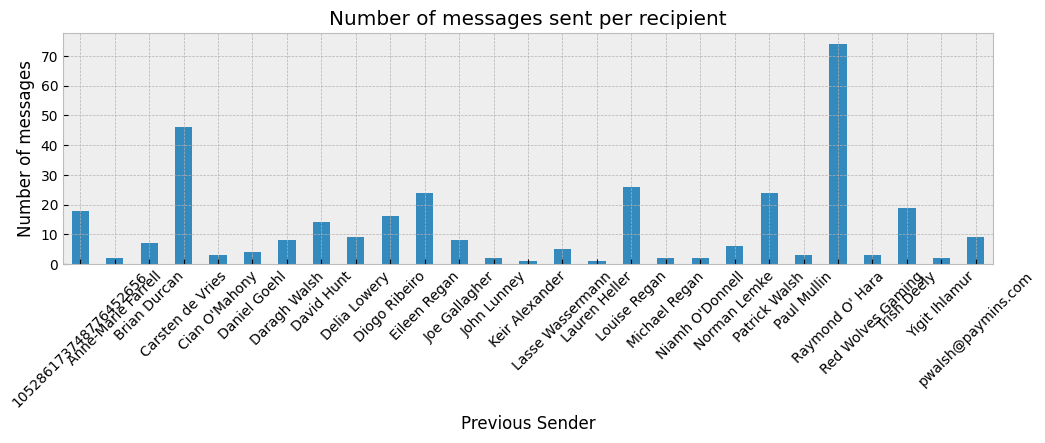

In [ ]:
ax = messages.groupby('prev_sender')['conversation_id'].size().plot(
    kind='bar', figsize=(12,3), title='Number of messages sent per recipient', color=colors[0])
_ = ax.set_xlabel('Previous Sender')
_ = ax.set_ylabel('Number of messages')
_ = plt.xticks(rotation=45)

In [4]:
messages['prev_sender'].unique()

array(['Keir Alexander', 'Louise Regan', 'Daragh Walsh', 'David Hunt',
       'Trish Deely', 'Daniel Goehl', 'Carsten de Vries', 'Norman Lemke',
       'Michael Regan', "Raymond O' Hara", 'Anne-Marie Farrell',
       "Niamh O'Donnell", 'Joe Gallagher', 'Delia Lowery',
       'Diogo Ribeiro', 'Yigit Ihlamur', 'Patrick Walsh', 'Paul Mullin',
       'Lasse Wassermann', 'Eileen Regan', 'pwalsh@paymins.com',
       'Red Wolves Gaming', 'John Lunney', '105286173748776452656',
       'Brian Durcan', "Cian O'Mahony", 'Lauren Heller'], dtype=object)

In [5]:
print(messages.loc[messages['prev_sender'] == 'Patrick Walsh','time_delay_seconds'].mean())
print(messages.loc[messages['prev_sender'] == 'Eileen Regan','time_delay_seconds'].mean())

18.791666666666668
24.708333333333332


For each message j and each conversation i, we represent the model as:

$$y_{ji} \sim NegBinomial(\mu_i, \alpha_i)$$
$$\mu_i = Uniform(0, 100)$$
$$\alpha_i = Uniform(0, 100)$$

In [6]:
# Convert categorical variables to integer
le = preprocessing.LabelEncoder()
participants_idx = le.fit_transform(messages['prev_sender'])
participants = le.classes_
n_participants = len(participants)


## Negative Binomial in PyMc
### In probability we are used to the folwoing notation:
### $X\sim NB(r,p)$, where $r$ is the number of successes required and p is the probability.
### PyMc has an altervative way to represent the Negative Binomial distributrion:

### $X\sim NB(\mu,\alpha)$, where $\mu$ is the expected value and $\alpha$ is the dispersion parameter. This means:

### $$ V(X) = \mu + \alpha \mu^2 $$.

### Thus, the variance is computed via $\alpha$ and $\mu$. The larger $\alpha$ is the larger the variance =.

In [8]:
indiv_traces = {}

# Convert categorical variables to integer
le = preprocessing.LabelEncoder()
participants_idx = le.fit_transform(messages['prev_sender'])
participants = le.classes_
n_participants = len(participants)

for p in participants:
    with pm.Model() as model:
        alpha = pm.Uniform('alpha', lower=0, upper=100)
        mu = pm.Uniform('mu', lower=0, upper=100)

        data = messages[messages['prev_sender']==p]['time_delay_seconds'].values
        y_est = pm.NegativeBinomial('y_est', mu=mu, alpha=alpha, observed=data)

        y_pred = pm.NegativeBinomial('y_pred', mu=mu, alpha=alpha)

        start = pm.find_MAP()
        step = pm.Metropolis()
        trace = pm.sample(2000, step=step, initvals=start)

        indiv_traces[p] = trace

Output()

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Output()

Output()

...

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Output()

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


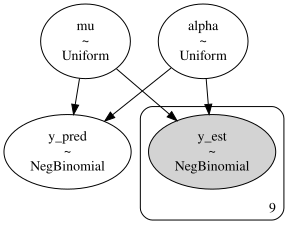

In [9]:
pm.model_to_graphviz(model)

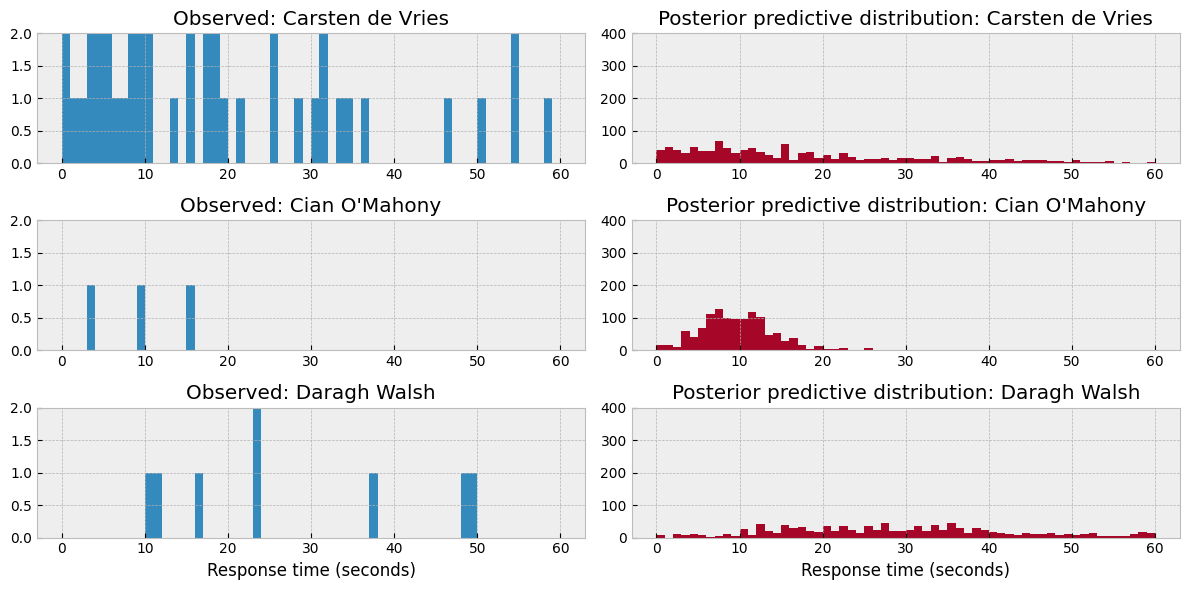

In [10]:
fig, axs = plt.subplots(3,2, figsize=(12, 6))
axs = axs.ravel()
y_left_max = 2
y_right_max = 400
x_lim = 60
ix = [3,4,6]

for i, j, p in zip([0,1,2], [0,2,4], participants[ix]):
    axs[j].set_title('Observed: %s' % p)
    axs[j].hist(messages[messages['prev_sender']==p]['time_delay_seconds'].values, range=[0, x_lim], bins=x_lim, histtype='stepfilled')
    axs[j].set_ylim([0, y_left_max])

for i, j, p in zip([0,1,2], [1,3,5], participants[ix]):
    axs[j].set_title('Posterior predictive distribution: %s' % p)
    axs[j].hist(np.array(indiv_traces[p].posterior['y_pred']).flatten(), range=[0, x_lim], bins=x_lim, histtype='stepfilled', color=colors[1])
    axs[j].set_ylim([0, y_right_max])

axs[4].set_xlabel('Response time (seconds)')
axs[5].set_xlabel('Response time (seconds)')

plt.tight_layout()

The above plots show the observed data (left) and the posterior predictive distribution (right) for 3 example conversations we modeled. As you can see, the posterior predictive distribution can vary considerably across conversations. This could accurately reflect the characteristics of the conversation or it could be inaccurate due to small sample size.

If we combine the posterior predictive distributions across these models, we would expect this to resemble the distribution of the overall dataset observed. Let's perform the posterior predictive check.

In [11]:
trace.posterior['y_pred']

<xarray.DataArray 'y_pred' (chain: 2, draw: 600)> Size: 10kB
array([[25, 25, 20, ..., 38, 34, 34],
       [12, 14, 14, ..., 14, 32, 32]])
Coordinates:
  * chain    (chain) int64 16B 0 1
  * draw     (draw) int64 5kB 0 1 2 3 4 5 6 7 ... 593 594 595 596 597 598 599

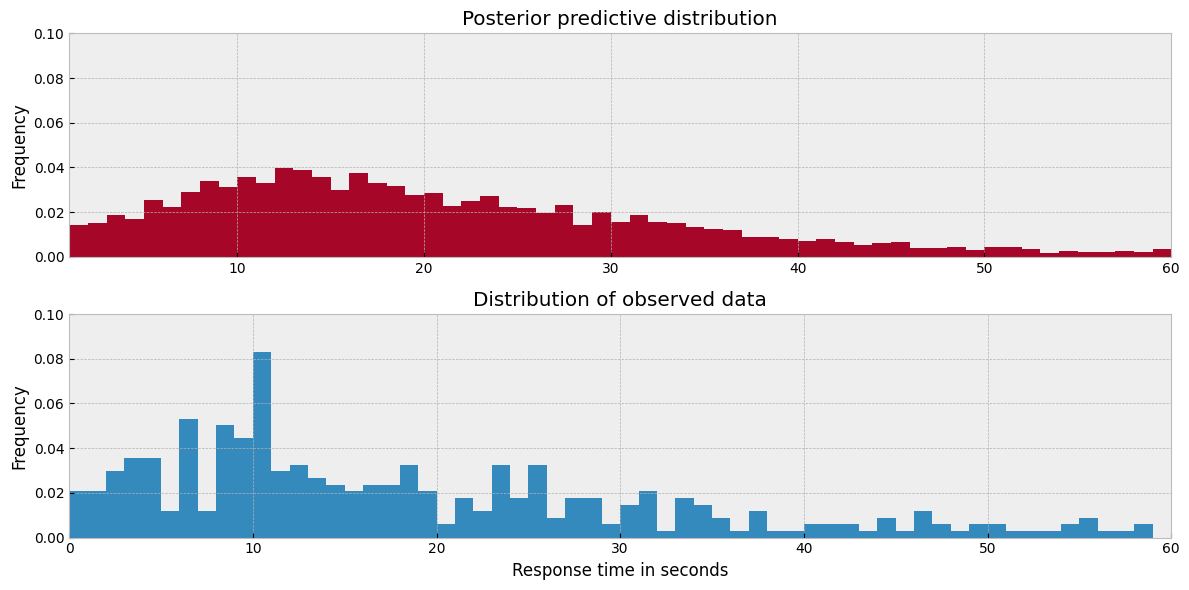

In [13]:
combined_y_pred = np.concatenate([v.posterior.y_pred[0] for k, v in indiv_traces.items()])

x_lim = 60
# y_pred = trace['y_pred']

fig = plt.figure(figsize=(12,6))
fig.add_subplot(211)

# fig.add_subplot(211)

_ = plt.hist(combined_y_pred, range=[0, x_lim], bins=x_lim, histtype='stepfilled', color=colors[1], density = True)
_ = plt.xlim(1, x_lim)
_ = plt.ylim(0, 0.1)
_ = plt.ylabel('Frequency')
_ = plt.title('Posterior predictive distribution')

fig.add_subplot(212)

_ = plt.hist(messages['time_delay_seconds'].values, range=[0, x_lim], bins=x_lim, histtype='stepfilled', density = True)
_ = plt.xlim(0, x_lim)
_ = plt.xlabel('Response time in seconds')
_ = plt.ylim(0, 0.1)
_ = plt.ylabel('Frequency')
_ = plt.title('Distribution of observed data')

plt.tight_layout()

Yes, the posterior predictive distribution resembles the distribution of the observed data. However, I'm concerned that some of the conversations have very little data and hence the estimates are likely to have high variance. One way to mitigate this risk to to share information across conversations - but still estimate $\mu_i$ for each conversation. We call this partial pooling.

### Partial pooling
Just like in the pooled model, a partially pooled model has paramater values estimated for each conversation i. However, parameters are connected together via hyperparameters. This reflects our belief that my `response_time`'s per conversation have similarities with one another via my own natural tendancy to respond quickly or slowly.

$$y_{ji} \sim NegBinomial(\mu_i, \alpha_i)$$

Following on from the above example, we will estimate parameter values $(\mu_i)$ and $(\alpha_i)$ for a Gamma distribution. Rather than using a uniform prior, I will use a Gamma distribution for both $\mu$ and $\sigma$. This will enable me to introduce more prior knowledge into the model as I have certain expectations as to what vales $\mu$ and $\sigma$ will be.

First, let's have a look at the Gamma distribution. As you can see below, it is very flexible.

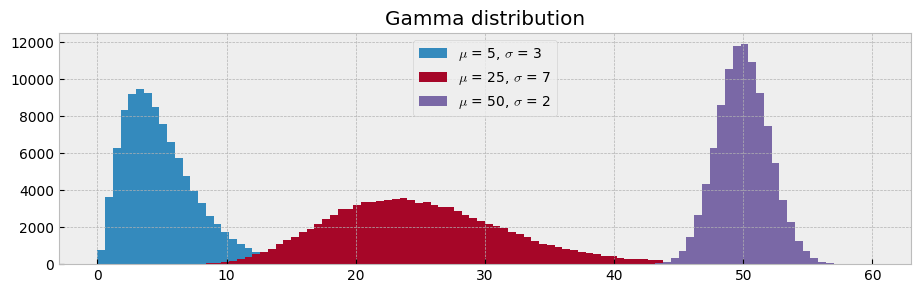

In [ ]:
mu = [5,25,50]
sd = [ 3,7,2]

plt.figure(figsize=(11,3))
_ = plt.title('Gamma distribution')

with pm.Model() as model:
    for i, (j, k) in enumerate(zip(mu, sd)):
        gamma_var = pm.Gamma('gamma_%s' % i, mu=j, sigma=k)
        samples = pm.draw(gamma_var, draws=10**5)

        # .random(size=10**6)
        plt.hist(samples, bins=100, range=(0,60), color=colors[i], alpha=1)

_ = plt.legend(['$\mu$ = %s, $\sigma$ = %s' % (mu[a], sd[a]) for a in [0,1,2]])

The partially pooled model can be formally described by:

$$y_{ji} \sim NegBinomial(\mu_i, \alpha_i)$$
$$\mu_i = Gamma(\mu_\mu, \sigma_\mu)$$
$$\alpha_i = Gamma(\mu_\alpha, \sigma_\alpha)$$
$$\mu_\mu = Uniform(0, 60)$$
$$\sigma_\mu = Uniform(0, 50)$$
$$\mu_\alpha = Uniform(0, 10)$$
$$\sigma_\alpha = Uniform(0, 50)$$

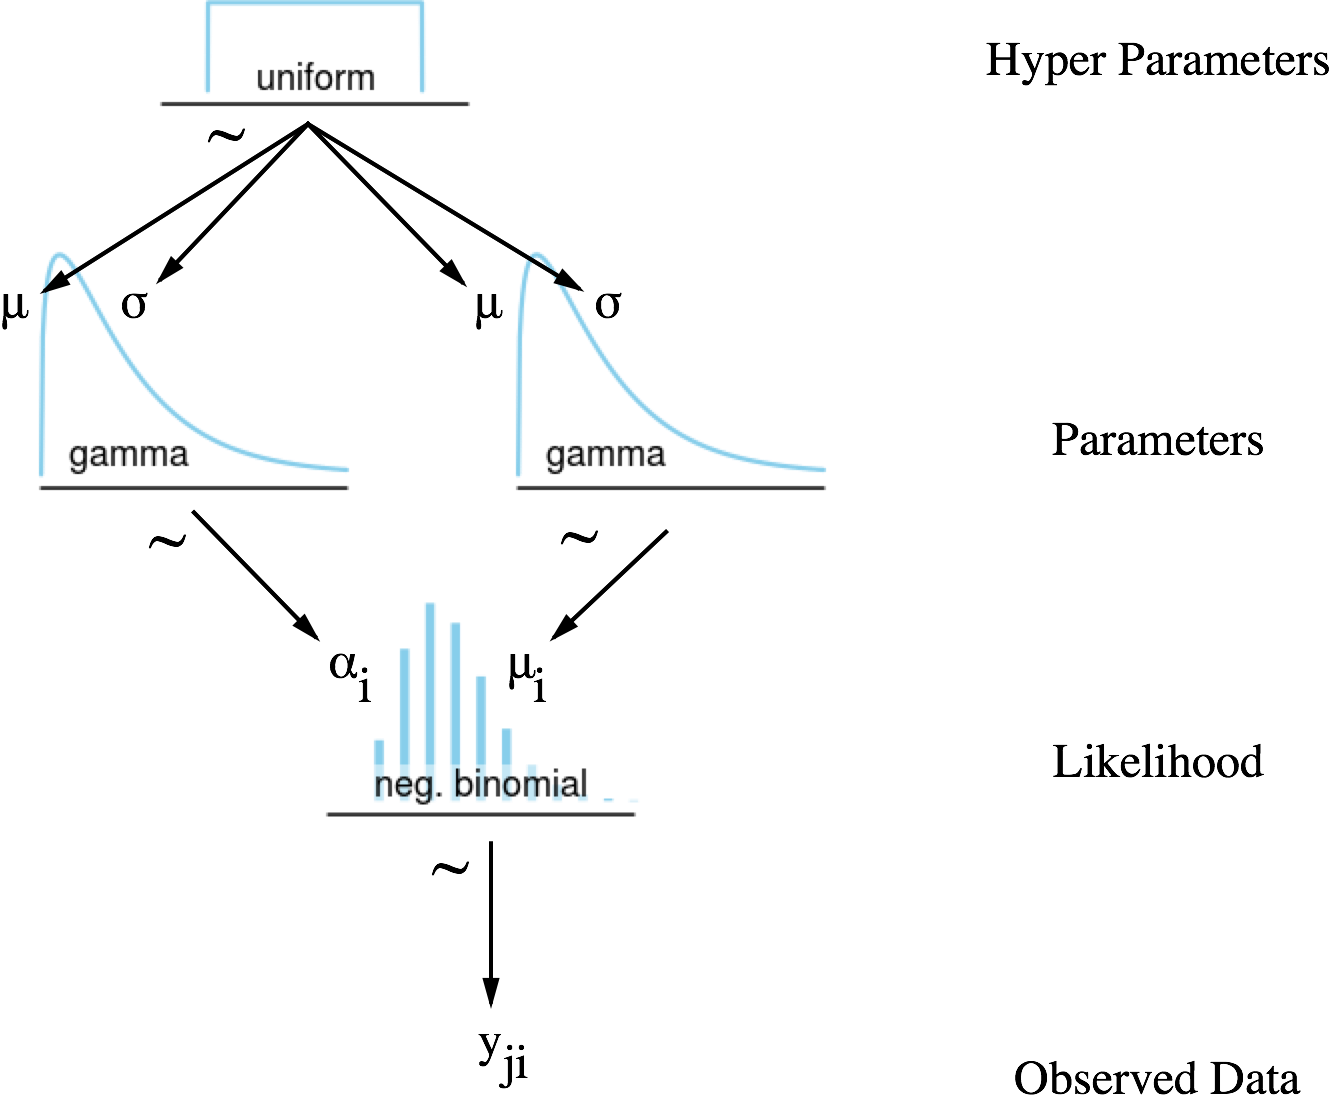

In [ ]:
Image('graphics/dag neg poisson gamma hyper.png', width=420)

In [14]:
with pm.Model() as model_hir:

    hyper_alpha_sd = pm.Uniform('hyper_alpha_sd', lower=0, upper=50)
    hyper_alpha_mu = pm.Uniform('hyper_alpha_mu', lower=0, upper=10)

    hyper_mu_sd = pm.Uniform('hyper_mu_sd', lower=0, upper=50)
    hyper_mu_mu = pm.Uniform('hyper_mu_mu', lower=0, upper=60)

    alpha = pm.Gamma('alpha', mu=hyper_alpha_mu, sigma=hyper_alpha_sd, shape=n_participants)
    mu = pm.Gamma('mu', mu=hyper_mu_mu, sigma=hyper_mu_sd, shape=n_participants)

    y_est = pm.NegativeBinomial('y_est',
                                mu=mu[participants_idx],
                                alpha=alpha[participants_idx],
                                observed=messages['time_delay_seconds'].values)

    y_pred = pm.NegativeBinomial('y_pred',
                                 mu=mu[participants_idx],
                                 alpha=alpha[participants_idx],
                                 shape=messages['prev_sender'].shape)

    start = pm.find_MAP()
    step = pm.Metropolis()
    hierarchical_trace = pm.sample(1000, tune= 150, step=step, progressbar=True)

Output()

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


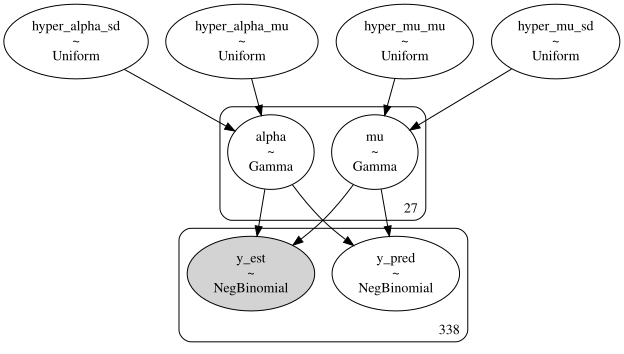

In [15]:
pm.model_to_graphviz(model_hir)

In [ ]:
import pickle as pkl
pkl.dump(hierarchical_trace, open('hierarchical_trace.pkl', 'wb'))

In [16]:
mu_trace = hierarchical_trace.posterior['mu']

## Comparing the mu parameter for different groups

In [ ]:
np.array(indiv_traces[p].posterior['mu']).flatten()[1000:].shape

(3000,)

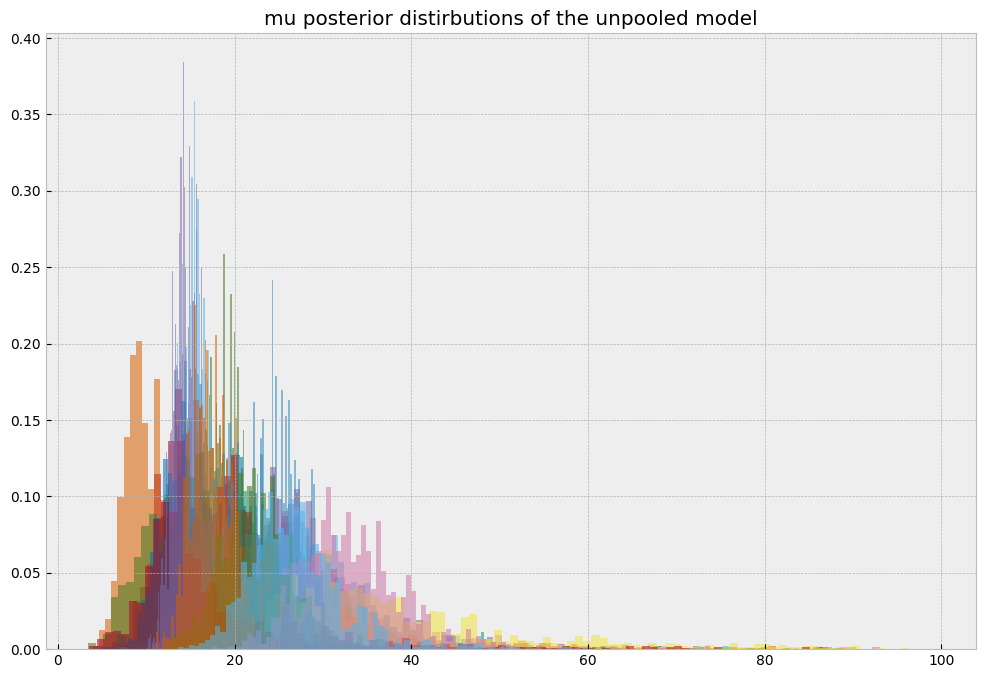

In [ ]:
mean_mus_unpooled = []
plt.figure(figsize=(12,8))
for p in participants:
    mu_trace_unpooled = np.array(indiv_traces[p].posterior['mu']).flatten()
    plt.hist(mu_trace_unpooled[1000:], density = True, bins =100, alpha = 0.55)
    mean_mus_unpooled.append(mu_trace_unpooled.mean())

plt.title('mu posterior distirbutions of the unpooled model')
plt.show()

In [ ]:
participants.shape[0]

27

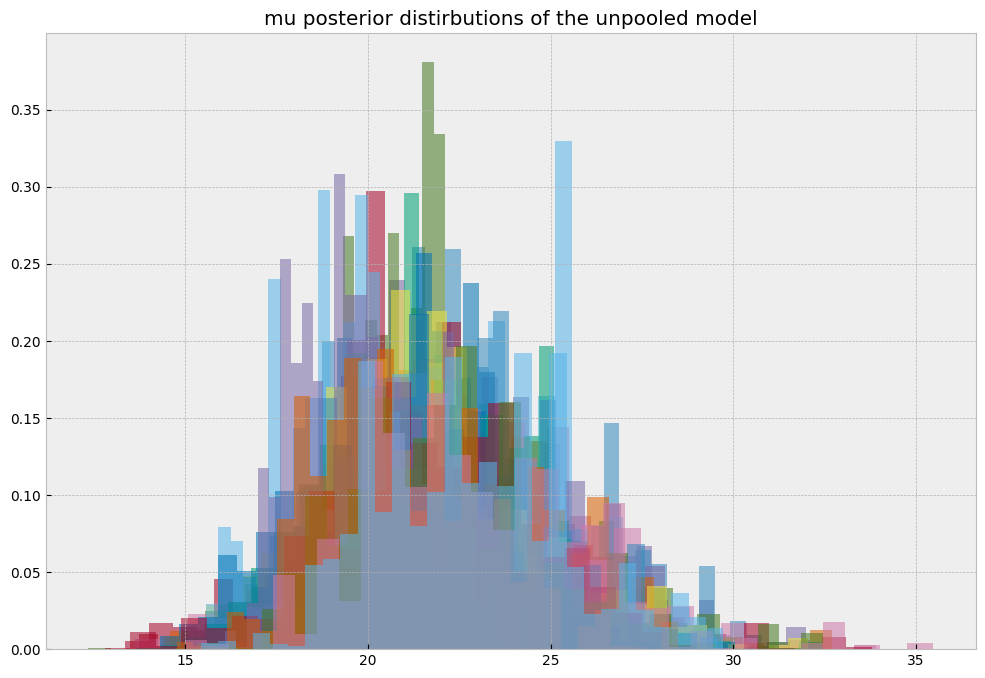

In [ ]:
mean_mus_pooled = []
plt.figure(figsize=(12,8))
for ind_p in range(participants.shape[0]):
    mu_trace_pooled = np.array(mu_trace[:,:,ind_p]).flatten()
    plt.hist(np.array(mu_trace[:,:,ind_p]).flatten(), density = True, bins =30, alpha = 0.55)
    mean_mus_pooled.append(mu_trace_pooled.mean())

plt.title('mu posterior distirbutions of the pooled model')
plt.show()

As we can see, the mu values of the hierarchical is way more narrow than the unpooled model.

You can see for the estimates of $\mu$ and $\alpha$ that we have multiple plots - one for each conversation i. The difference between the pooled and the partially pooled model is that the parameters of the partially pooled model ($\mu_i$ and $\alpha_i$) have a hyperparameter that is shared across all conversations i. This brings two benefits:
1. Information is shared across conversations, so for conversations that have limited sample size, they "borrow" knowledge from other conversations during estimation to help reduce the variance of the estimate
2. We get an estimate for each conversation and an overall estimate for all conversations

Let's have a quick look at the posterior predictive distribution.

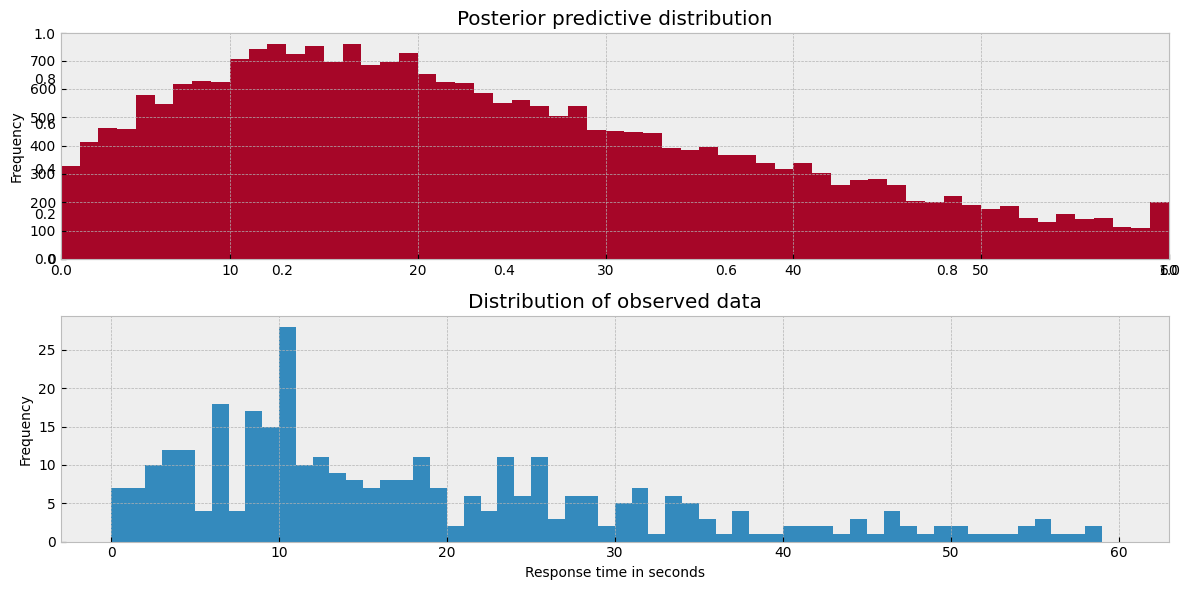

In [ ]:
x_lim = 60
y_pred = hierarchical_trace.get_values('y_pred')[::1000].ravel()

fig = plt.figure(figsize=(12,6))
fig.add_subplot(211)

fig.add_subplot(211)

_ = plt.hist(y_pred, range=[0, x_lim], bins=x_lim, histtype='stepfilled', color=colors[1])
_ = plt.xlim(1, x_lim)
_ = plt.ylabel('Frequency')
_ = plt.title('Posterior predictive distribution')

fig.add_subplot(212)

_ = plt.hist(messages['time_delay_seconds'].values, range=[0, x_lim], bins=x_lim, histtype='stepfilled')
_ = plt.xlabel('Response time in seconds')
_ = plt.ylabel('Frequency')
_ = plt.title('Distribution of observed data')

plt.tight_layout()

### Shrinkage effect: pooled vs hierarchical model
As discussed, the partially pooled model shared a hyperparameter for both $\mu$ and $\alpha$. By sharing knowledge across conversations, it has the effect of shrinking the estimates closer together - particularly for conversations that have little data.

This shrinkage effect is illustrated in the below plot. You can see how the $\mu$ and $\alpha$ parameters are drawn together by the effect of the hyperparameter.

In [ ]:
hierarchical_trace

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

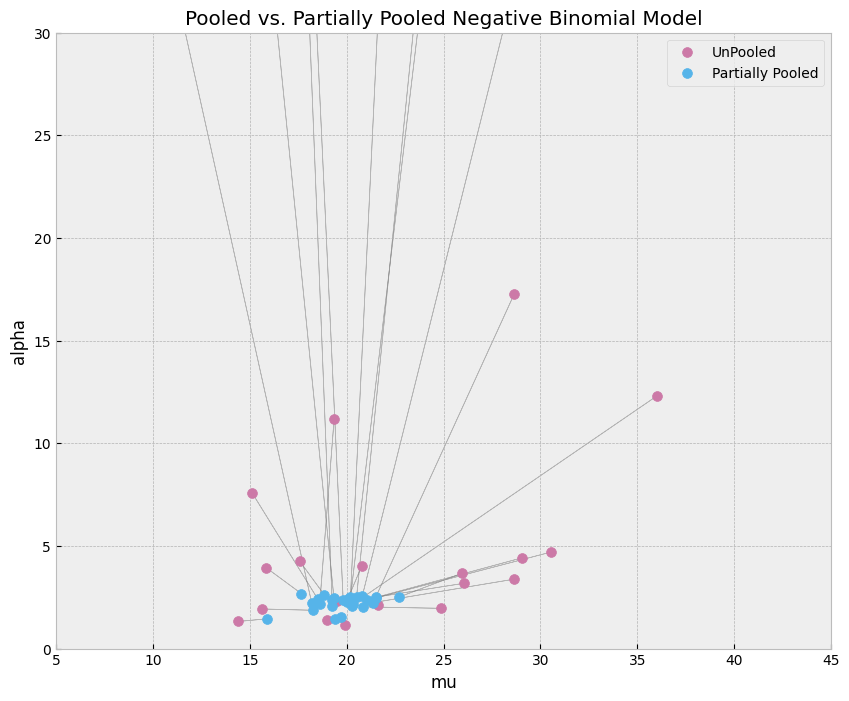

In [17]:
hier_mu = np.mean(np.array(hierarchical_trace.posterior['mu']),axis=(0, 1))
hier_alpha = np.mean(np.array(hierarchical_trace.posterior['alpha']),axis=(0, 1))
indv_mu = [np.array(indiv_traces[p].posterior['mu']).mean().item() for p in participants]
indv_alpha = [np.array(indiv_traces[p].posterior['alpha']).mean().item() for p in participants]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, xlabel='mu', ylabel='alpha',
                     title='Pooled vs. Partially Pooled Negative Binomial Model',
                     xlim=(5, 45), ylim=(0,30))

ax.scatter(indv_mu, indv_alpha, c=colors[5], s=50, label = 'UnPooled', zorder=3)
ax.scatter(hier_mu, hier_alpha, c=colors[6], s=50, label = 'Partially Pooled', zorder=4)
for i in range(len(indv_mu)):
    ax.arrow(indv_mu[i], indv_alpha[i], hier_mu[i] - indv_mu[i], hier_alpha[i] - indv_alpha[i],
            fc="grey", ec="grey", length_includes_head=True, alpha=.5, head_width=0)

_ = ax.legend()

### Asking questions of the posterior
Let's start to take advantage of one of the best aspects of Bayesian statistics - the posterior distribution. Unlike frequentist techniques, we get a full posterior distribution as opposed to a single point estimate. In essence, we have a basket full of credible parameter values. This enables us to ask some questions in a fairly natural and intuitive manner.

#### What are the chances I'll respond to my friend in less than 10 seconds?
To estimate this probability, we can look at the posterior predctive distribution for Timothy & Andrew's `response_time` and check how many of the samples are < 10 seconds.

In [23]:
ix = messages.loc[messages['prev_sender']==participants[3],:].index
np.array(hierarchical_trace.posterior['y_pred'][:,:, ix]).flatten()

array([ 23,  21, 121, ...,  12,  18,  56])

In [29]:
def participant_y_pred(person):
    """Return posterior predictive for person"""
    ix = messages.loc[messages['prev_sender']==person,:].index
    return np.array(hierarchical_trace.posterior['y_pred'][:,:, ix]).flatten()

In [30]:
print("Here are some samples from John Lunney's posterior predictive distribution: \n %s" % participant_y_pred('John Lunney'))

Here are some samples from John Lunney's posterior predictive distribution: 
 [ 16  37  16 ... 100  41 103]


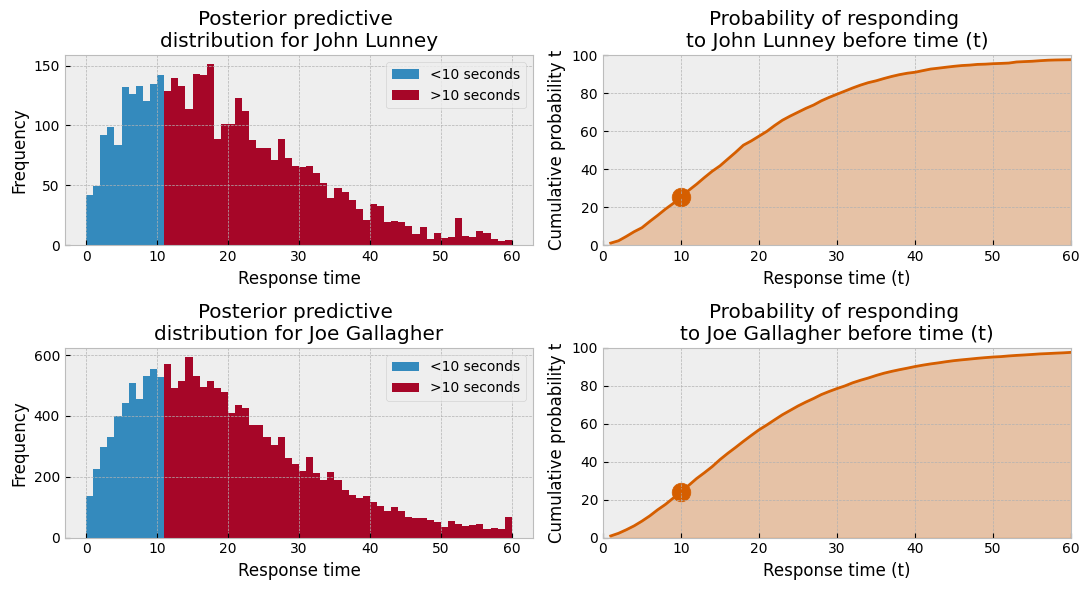

In [32]:
def person_plotA(person_name):
    ix_check = participant_y_pred(person_name) > 10
    _ = plt.hist(participant_y_pred(person_name)[~ix_check], range=[0, x_lim], bins=x_lim, histtype='stepfilled', label='<10 seconds')
    _ = plt.hist(participant_y_pred(person_name)[ix_check], range=[0, x_lim], bins=x_lim, histtype='stepfilled', label='>10 seconds')
    _ = plt.title('Posterior predictive \ndistribution for %s' % person_name)
    _ = plt.xlabel('Response time')
    _ = plt.ylabel('Frequency')
    _ = plt.legend()

def person_plotB(person_name):
    x = np.linspace(1, 60, num=60)
    num_samples = float(len(participant_y_pred(person_name)))
    prob_lt_x = [100*sum(participant_y_pred(person_name) < i)/num_samples for i in x]
    _ = plt.plot(x, prob_lt_x, color=colors[4])
    _ = plt.fill_between(x, prob_lt_x, color=colors[4], alpha=0.3)
    _ = plt.scatter(10, float(100*sum(participant_y_pred(person_name) < 10))/num_samples, s=180, c=colors[4])
    _ = plt.title('Probability of responding \nto %s before time (t)' % person_name)
    _ = plt.xlabel('Response time (t)')
    _ = plt.ylabel('Cumulative probability t')
    _ = plt.ylim(ymin=0, ymax=100)
    _ = plt.xlim(xmin=0, xmax=60)

fig = plt.figure(figsize=(11,6))
_ = fig.add_subplot(221)
person_plotA('John Lunney')
_ = fig.add_subplot(222)
person_plotB('John Lunney')

_ = fig.add_subplot(223)
person_plotA('Joe Gallagher')
_ = fig.add_subplot(224)
person_plotB('Joe Gallagher')

plt.tight_layout()

I find this methodology to be very intuitive and flexible. The plot above left separates the samples from the posterior predictive in terms of being greater than or less than 10 seconds. We can compute the probability by calculating the proportion of samples that are less than 10. The plot on the right simply computes this probability for each response time value from 0 to 60. So, it looks like Anna & Yonas have a 36% & 20% chance of being responded to in less than 10 seconds, respectively.

#### How do my friends pair off against each other?

In [ ]:
sum(participant_y_pred(participants[1]))

np.int64(100431)

In [ ]:
participant_y_pred(participants[4]).shape

(6000,)

In [40]:
def prob_persona_faster(persona, personb):
    """Return probability that persona is faster than personb"""
    size_a = participant_y_pred(persona).shape[0]
    size_b = participant_y_pred(personb).shape[0]
    min_size =  min(size_a, size_b)
    return (sum(participant_y_pred(persona)[:min_size] < participant_y_pred(personb)[:min_size]))/min_size

print("Probability that John Lunney is responded to faster than Joe Gallagher: {:.2%}".format(prob_persona_faster('John Lunney', 'Joe Gallagher')))

Probability that John Lunney is responded to faster than Joe Gallagher: 48.27%


In [42]:
participant_y_pred

<function __main__.participant_y_pred(person)>

In [44]:
hierarchical_trace.posterior['y_pred'].shape

(2, 1000, 338)

In [47]:
ix = messages.loc[messages['prev_sender']=='Joe Gallagher',:].index
ix

Index([138, 139, 140, 141, 142, 143, 144, 145], dtype='int64')

In [ ]:
np.array(hierarchical_trace.posterior['y_pred'][:,:, ix]).flatten()